In [12]:
import pandas as pd
import yaml 
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from decimal import Decimal
from datetime import datetime
from dateutil import parser
import networkx as nx

data exploration

In [13]:
df_users = pd.read_csv('users.csv')
df_users = pd.DataFrame(df_users)

df_books = yaml.safe_load(open('books.yaml'))
df_books = pd.DataFrame(df_books)

df_orders = pq.read_table('orders.parquet').to_pandas()
df_orders = pq.ParquetDataset('orders.parquet').read().to_pandas()

In [14]:
df_users.head()
len(df_users)
df_users.info()

df_users.duplicated().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3319 entries, 0 to 3318
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       3319 non-null   int64
 1   name     3319 non-null   str  
 2   address  3189 non-null   str  
 3   phone    3319 non-null   str  
 4   email    3319 non-null   str  
dtypes: int64(1), str(4)
memory usage: 455.2 KB


np.int64(0)

In [15]:
print(type(df_books))
df_books.info()
print(df_books.isna().sum(), "\n")
print(df_books.duplicated().sum())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 770 entries, 0 to 769
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   :id         770 non-null    int64 
 1   :title      770 non-null    str   
 2   :author     770 non-null    str   
 3   :genre      770 non-null    str   
 4   :publisher  770 non-null    str   
 5   :year       768 non-null    object
dtypes: int64(1), object(1), str(4)
memory usage: 87.4+ KB
:id           0
:title        0
:author       0
:genre        0
:publisher    0
:year         2
dtype: int64 

0


In [16]:
len(df_orders)
df_orders.info()
print(df_orders.isna().sum(), "\n")
print(df_orders.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9181 entries, 0 to 9180
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          9181 non-null   int64
 1   user_id     9181 non-null   int64
 2   book_id     9181 non-null   int64
 3   quantity    9181 non-null   int32
 4   unit_price  9181 non-null   str  
 5   timestamp   9181 non-null   str  
 6   shipping    6943 non-null   str  
dtypes: int32(1), int64(3), str(3)
memory usage: 829.1 KB
id               0
user_id          0
book_id          0
quantity         0
unit_price       0
timestamp        0
shipping      2238
dtype: int64 

0


In [17]:
print(df_users.isna().sum(), "\n")
print(df_users.duplicated().sum())



id           0
name         0
address    130
phone        0
email        0
dtype: int64 

0


data cleaning

In [18]:
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].unique(), "\n")
print(df_orders['timestamp'].head(20))

0       EUR 60
1      51.25 $
2       $70¢50
3      $ 59.25
4    USD 66.99
5      46.5USD
6       61.0 $
7    USD 57.00
8      49.25 $
9       $ 13.0
Name: unit_price, dtype: str 

<ArrowStringArray>
[   'EUR 60',   '51.25 $',    '$70¢50',   '$ 59.25', 'USD 66.99',   '46.5USD',
    '61.0 $', 'USD 57.00',   '49.25 $',    '$ 13.0',
 ...
     '€53.0',      '€ 62',    '72.75$',    '74.5 $',     '€34.5',   '48.0USD',
  '61.5 USD',     'USD25',  '70.5 EUR',   '70.75 €']
Length: 5636, dtype: str 

0               4-July-2025 16:44
1         07:08:51 PM,11-Nov-2025
2             16-March-2026,19:00
3            10:06:35 am 06/16/25
4        Sun Nov 23 06:06:05 2025
5         2026-02-21T15:51:06.911
6            16:34:05, 2025-02-09
7            11:57:09, 2025-08-12
8            03/09/26 04:29:04 pm
9         25-Jul-2025 05:58:07 AM
10        10:14:18 am 29-MAR-2026
11        2025-06-11T20:35:35.223
12           09:28:36, 2026-01-10
13               2025-05-29,21:11
14         12:14:43 P.M. 02/

In [19]:
print(df_books[':year'].unique()[:20], "\n")

[1993 '-1' 1983 2015 2011 1991 1982 2017 2016 1988 2005 1987 1865 2025
 1992 2008 1998 2020 None 2019] 



In [20]:
#function to change currency to usd and clean signs such as $ or eur

def convert_to_usd(unit_price):
    clean_price = unit_price.replace("$", "").replace("EUR", "").replace("€", "").replace("USD", "").replace("¢", ".").strip()

    if unit_price.startswith("€") and "¢" in unit_price:
        return Decimal(unit_price[1:].replace("¢", ".")) * Decimal("1.2")

    if unit_price.startswith("$") and "¢" in unit_price:
        return Decimal(unit_price[1:].replace("¢", "."))

    if "€" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("€", ".").replace("¢", "")
        return Decimal(clean_price) * Decimal("1.2")

    if "$" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("$", ".").replace("¢", "")
        return Decimal(clean_price)
    value = Decimal(clean_price)
    if "EUR" in unit_price or "€" in unit_price:
        currency = value * Decimal("1.2")
    elif "$" in unit_price or "USD" in unit_price:
        currency = value
    else:
        raise ValueError("Unsupported currency")
    
    return currency

In [21]:
raw = pd.read_parquet("orders.parquet")

mask = raw["unit_price"].str.contains(
    r"^[€$]\d+¢\d+$",
    regex=True,
    na=False
)

print("Affected orders:", mask.sum())
print("Total orders:", len(raw))
print("Affected percentage:", round(mask.mean() * 100, 2), "%")

Affected orders: 530
Total orders: 9181
Affected percentage: 5.77 %


In [22]:
print(convert_to_usd("EUR72.75"))  # test

87.300


In [23]:
df_orders['unit_price'] = df_orders['unit_price'].apply(convert_to_usd)
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].isna().sum())

0     72.0
1    51.25
2    70.50
3    59.25
4    66.99
5     46.5
6     61.0
7    57.00
8    49.25
9     13.0
Name: unit_price, dtype: object 

0


In [24]:
#paid price = quentity * unit_price
df_orders['paid_price'] = df_orders['quantity'] * df_orders['unit_price']
print(df_orders[['quantity', 'unit_price', 'paid_price']].head(20))


    quantity unit_price paid_price
0          1       72.0       72.0
1          1      51.25      51.25
2          2      70.50     141.00
3          1      59.25      59.25
4          1      66.99      66.99
5          1       46.5       46.5
6          1       61.0       61.0
7          2      57.00     114.00
8          1      49.25      49.25
9          3       13.0       39.0
10         1      12.75      12.75
11         1      32.99      32.99
12         1      64.99      64.99
13         5       80.4      402.0
14         4       33.5      134.0
15         1       27.6       27.6
16         1     22.500     22.500
17         1      49.00      49.00
18         1         55         55
19         1     47.100     47.100


In [25]:
def timestamp_parser(value):
    try:
        value = str(value).strip()
        value = value.replace(",", " ").replace(";"," ")
        value = value.replace("A.M.", "AM").replace("P.M.", "PM")
        return parser.parse(value)
    except(ValueError, TypeError):
        return pd.NaT
    

In [26]:
df_orders['parsed_timestamp'] = df_orders['timestamp'].apply(timestamp_parser)
print(df_orders['parsed_timestamp'].isna().sum())

0


In [27]:
print(df_orders.columns.tolist())

['id', 'user_id', 'book_id', 'quantity', 'unit_price', 'timestamp', 'shipping', 'paid_price', 'parsed_timestamp']


In [28]:
df_orders['date'] = pd.to_datetime(df_orders['parsed_timestamp']).dt.date
print(df_orders[['parsed_timestamp', 'date']].head(5))

     parsed_timestamp        date
0 2025-07-04 16:44:00  2025-07-04
1 2025-11-11 19:08:51  2025-11-11
2 2026-03-16 19:00:00  2026-03-16
3 2025-06-16 10:06:35  2025-06-16
4 2025-11-23 06:06:05  2025-11-23


In [29]:
daily_revenue = df_orders.groupby('date')['paid_price'].sum()
top5rev = daily_revenue.sort_values(ascending = False).head(5)
print(top5rev)

date
2025-11-16    3789.610
2025-12-12    3127.144
2025-12-10    3079.520
2025-09-19    2938.860
2025-11-19    2915.198
Name: paid_price, dtype: object


In [30]:
def same_user(user1, user2):
    columns = ['name', 'address', 'phone', 'email']
    matches = 0

    for col in columns:
        if pd.notna(user1[col]) and pd.notna(user2[col]):
            if user1[col] == user2[col]:
                matches += 1

    return matches >= 3

In [31]:
G = nx.Graph()
for user_id in df_users['id']:
    G.add_node(user_id)
for i in range(len(df_users)):
    for j in range(i + 1, len(df_users)):
        user1 = df_users.iloc[i]
        user2 = df_users.iloc[j]

        if same_user(user1, user2):
            G.add_edge(user1['id'], user2['id'])

In [32]:
groups = list(nx.connected_components(G))
unique_users_count = len(groups)
print("Total user ID:", len(df_users))
print("Unique users:", unique_users_count)

Total user ID: 3319
Unique users: 3166


In [33]:
user_mapping = {}
for group in groups:
    real_id = min(group)
    for user_id in group:
        user_mapping[user_id] = real_id

df_users['real_user_id'] = df_users['id'].map(user_mapping)
print(df_users[['id', 'real_user_id']].head(10))

      id  real_user_id
0  51519         51519
1  51034         51034
2  50943         50943
3  50193         50193
4  49580         49580
5  52039         52039
6  50320         50320
7  50007         50007
8  50483         50483
9  50897         50897


In [34]:
multiple_ids = [group for group in groups if len(group) > 1]

print("Users with multiple IDs:", len(multiple_ids))
print("Examples:", multiple_ids[:15])

Users with multiple IDs: 141
Examples: [{51832, np.int64(49531)}, {49633, np.int64(51396)}, {np.int64(49476), 49910}, {np.int64(50777), 50020}, {51104, np.int64(48859)}, {np.int64(48882), 50956}, {np.int64(51056), np.int64(51403), 49902}, {np.int64(51313), 50998, np.int64(51727)}, {np.int64(50153), 51220}, {np.int64(49173), 51893, np.int64(51575)}, {50882, np.int64(50115), np.int64(49102)}, {49352, np.int64(51596)}, {np.int64(49737), 50148}, {np.int64(51370), 50747, np.int64(49366)}, {np.int64(50700), 48974}]


In [35]:
print("Total groups:", len(groups))
print("Multiple ID groups:", len(multiple_ids))

for group in multiple_ids[:5]:
    display(df_users[df_users['id'].isin(group)])

Total groups: 3166
Multiple ID groups: 141


,id,name,address,phone,email,real_user_id
20,51832,Norma Keeling,"Suite 477 64128 Krystina Motorway, Cormiervill...",255-050-7748,shaunda@heller-gulgowski.example,49531
1899,49531,Norma Keeling,"Suite 108 9316 Leon Village, West Thurman, NJ ...",255-050-7748,shaunda@heller-gulgowski.example,49531


,id,name,address,phone,email,real_user_id
25,49633,Roy Gottlieb,"93955 Zboncak Hills, Johnsonberg, OR 01808-3434",139-284-2085,barrett@ratke.example,49633
177,51396,Roy Gottlieb,"93955 Zboncak Hills, Johnsonberg, OR 01808-3434",139-284-2085,augustine_leffler@schinner.example,49633


,id,name,address,phone,email,real_user_id
55,49910,Peter Abshire,"669 Pierre Shore, Sanfordberg, TX 07945",902.987.2497,clemencia@breitenberg.example,49476
389,49476,Peter Abshire,"765 Dannie Fords, New Casey, AK 97129-7179",902.987.2497,clemencia@breitenberg.example,49476


,id,name,address,phone,email,real_user_id
92,50020,Garfield Schoen,"Apt. 203 609 Albert Canyon, East Candancefort,...",882-929-9025,keely@watsica-lockman.test,50020
3144,50777,Garfield Schoen,"Apt. 203 609 Albert Canyon, East Candancefort,...",882-929-9025,lowell_schumm@conn.example,50020


,id,name,address,phone,email,real_user_id
117,51104,Avery Schneider,"Suite 499 4866 Grady Forest, Port Gustavostad,...",(443) 676-1773,veronica@quitzon.test,48859
2037,48859,Avery Schneider,"Suite 499 4866 Grady Forest, Port Gustavostad,...",678.229.4016,veronica@quitzon.test,48859


In [36]:
print("Largest group:", max(len(group) for group in groups))

Largest group: 3


In [37]:
missing_address = df_users[df_users['address'].isna()]

print("Missing addresses:", len(missing_address))
print("Unique real users:", missing_address['real_user_id'].nunique())

Missing addresses: 130
Unique real users: 130


In [38]:
print(df_books.columns.tolist())
print(df_books[':author'].head(10).to_string())

[':id', ':title', ':author', ':genre', ':publisher', ':year']
0    Gov. Tonja Mueller, Louis Fahey, Gov. Gale Harvey
1                                      Sharyl Bernhard
2                                           Linn Wolff
3      Foster Luettgen, Darrick Hagenes, Yun Jaskolski
4                                      Granville Kulas
5    Zula Pagac JD, Russ Jacobson, Belle Stroman, A...
6                                     Shantae Reynolds
7                     Aliza Sanford, Roselle McDermott
8                       Rashad Bergnaum, Lera Prohaska
9                                 Antonetta Daniel DDS


In [39]:
def split_names(authors):
    names = authors.split(",")
    names = [name.strip() for name in names]
    return frozenset(names)

In [40]:
df_books['authors'] = df_books[':author'].apply(split_names)
unique_authors = df_books['authors'].nunique()
print("Unique authors:", unique_authors)

Unique authors: 281


In [41]:
print(df_books[[':author', 'authors']].head(5))

                                             :author  \
0  Gov. Tonja Mueller, Louis Fahey, Gov. Gale Harvey   
1                                    Sharyl Bernhard   
2                                         Linn Wolff   
3    Foster Luettgen, Darrick Hagenes, Yun Jaskolski   
4                                    Granville Kulas   

                                             authors  
0  frozenset({Gov. Gale Harvey, Louis Fahey, Gov....  
1                       frozenset({Sharyl Bernhard})  
2                            frozenset({Linn Wolff})  
3  frozenset({Yun Jaskolski, Foster Luettgen, Dar...  
4                       frozenset({Granville Kulas})  


In [42]:
df_merged = df_orders.merge(df_books, left_on='book_id', right_on=':id')
author_sales = df_merged.groupby('authors')['quantity'].sum()
author_sales = author_sales.sort_values(ascending=False)

print(author_sales.head(5))

authors
frozenset({Kenneth Hamill, Marcus McKenzie})      176
frozenset({Nettie Howe, Pierre Runolfsson II})    173
frozenset({Rosanna Hamill})                       139
frozenset({Danica Graham})                        137
frozenset({Ayana Considine DO})                   121
Name: quantity, dtype: int32


In [43]:
df_orders['real_user_id'] = df_orders['user_id'].map(user_mapping)

print(df_orders[['user_id', 'real_user_id', 'paid_price']].head(10))
print("Missing users:", df_orders['real_user_id'].isna().sum())

buyer_spending = df_orders.groupby('real_user_id')['paid_price'].sum()
buyer_spending = buyer_spending.sort_values(ascending=False)

print(buyer_spending.head(5))
best_buyer = buyer_spending.index[0]

buyer_ids = df_users[df_users['real_user_id'] == best_buyer]['id'].tolist()

print("Best buyer IDs:", buyer_ids)
print("Total spending:", buyer_spending.iloc[0])

   user_id  real_user_id paid_price
0    48808         48808       72.0
1    49341         49341      51.25
2    49056         49056     141.00
3    49866         49866      59.25
4    51657         51657      66.99
5    51196         51196       46.5
6    50916         50916       61.0
7    50928         50928     114.00
8    50429         50429      49.25
9    49359         49359       39.0
Missing users: 0
real_user_id
51014    1131.070
50889    1077.340
49800     1048.40
48816    1016.180
50020    1015.780
Name: paid_price, dtype: object
Best buyer IDs: [51014]
Total spending: 1131.070


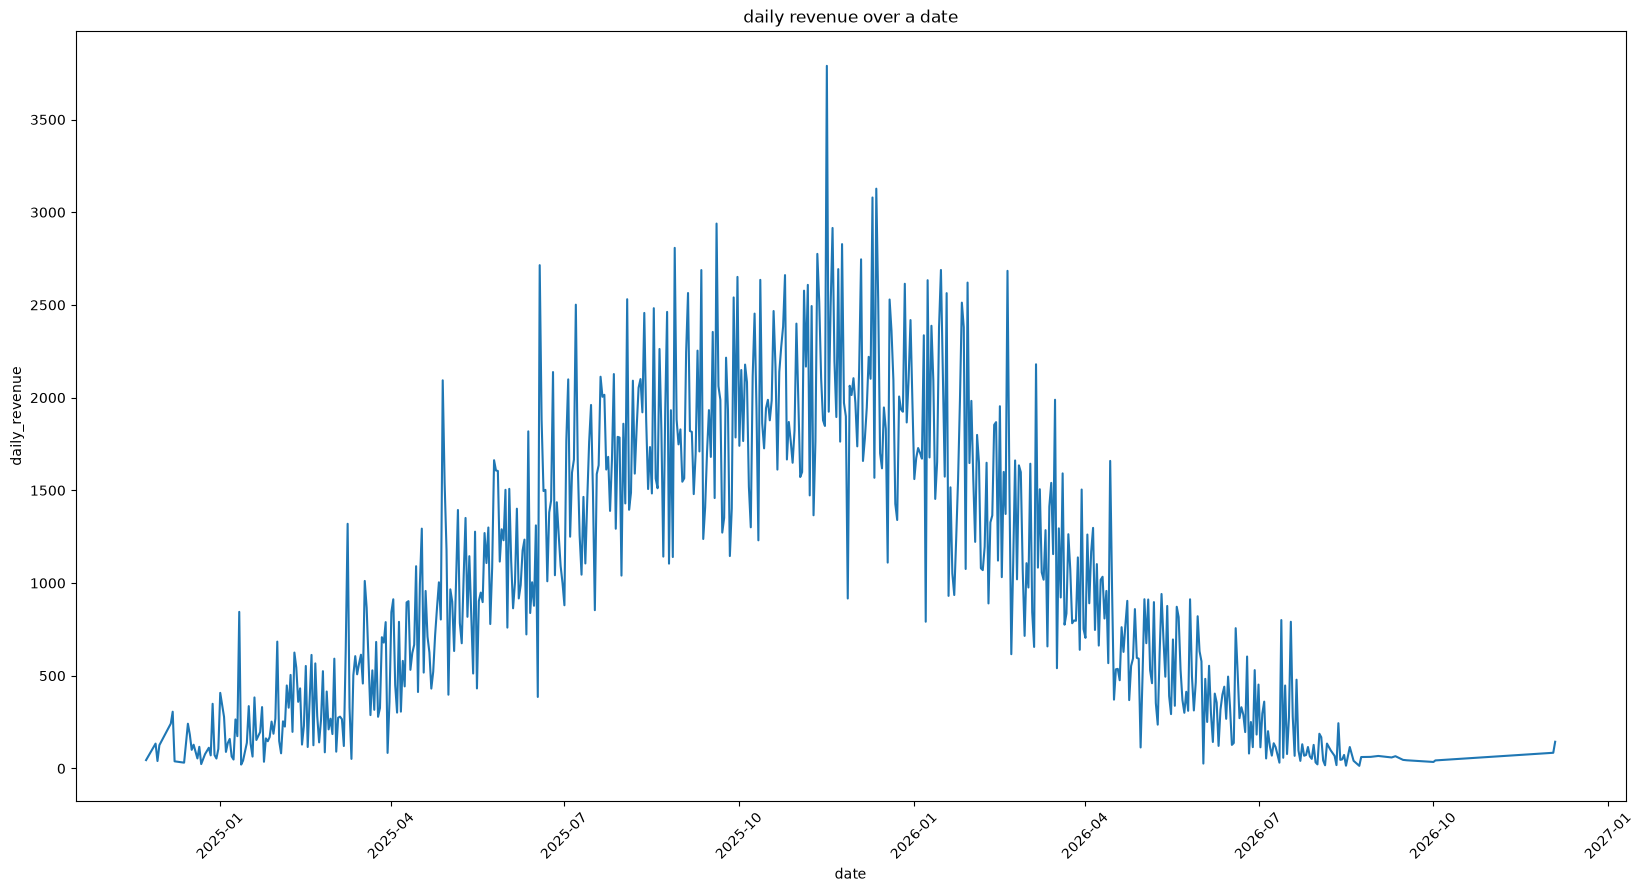

In [44]:
daily_revenue = daily_revenue.sort_index()
plt.figure(figsize=(20, 10))
plt.plot(daily_revenue.index, daily_revenue.astype(float))
plt.xlabel('date')
plt.xticks(rotation=45)
plt.ylabel('daily_revenue')
plt.title('daily revenue over a date')
plt.show()